# 03 · Long-only breakouts with crash-only shorts

**Idea.** The long-only breakout book earns the most, but it carries the full market crash: −60% in the GFC and about −44% in early 2020. The always-on long/short book avoids that, but its short leg loses money most of the time (in bull markets) and was hit hardest in the 2009 rebound.

This notebook tests a mix: **run long-only normally, and switch on a short leg only during a broad market crash.**

**What has to be decided**
1. **The crash signal:** when is "the market crashing"? It is measured on the ASX 200, using only data up to that day.
2. **The short instrument:**
   * **Index hedge:** short ASX 200 (SPI 200) futures against the long book, sized by its beta. This is cheap, easy to do in size, and was never banned.
   * **Single-stock shorts:** short the stocks breaking below their 250-day low (the strategy's own short signal), limited to the 200 most liquid names.

**Discipline.** The crash rule and the short type are chosen on **2006–2016 only**. That period contains a single crash, the GFC, so it is easy to fit a rule to one event. **COVID (2020) and the 2022 sell-off are the real out-of-sample test.**

Run `01_data_and_universe.ipynb` first.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RESULTS = Path("results")
TRADING_DAYS = 252
IS, OOS, FULL = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None), slice("2006-01-01", None)
BLUE, ORANGE, AQUA, YELLOW, GREY, RED_SOFT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a", "#f3c9c0"

d = pd.read_pickle("data/clean.pkl")
axjo = d["bench_ret"]["^AXJO"]
N, M = 250, 125

## 1. Engine

The signal function and drift engine are the same as in notebook 02, with two additions:

* **Per-day side budgets.** The short side's budget can switch between 0 and a target size from day to day. When it switches off, all shorts are closed (and charged). When it switches on, shorts are opened in the stocks the signal says.
* **Blocked short entries.** A mask can forbid *new* short entries on given days and stocks, to respect the GFC short-selling ban. Existing positions may be held, as was the case under the ban.

In [2]:
def channels(d, n):
    return (d["high"].rolling(n, min_periods=n).max().shift(1),
            d["low"].rolling(n, min_periods=n).min().shift(1))


def donchian_state(d, n, m, short_block=None):
    px, member = d["adj"], d["member"]
    up_n, lo_n = channels(d, n)
    up_m, lo_m = channels(d, m)
    short_in = px < lo_n
    if short_block is not None:
        short_in = short_in & ~short_block

    def state(enter, leave):
        s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
        return s.mask(leave | ~member, 0.0).mask(enter & member, 1.0).ffill().fillna(0.0)

    return state(px > up_n, px < lo_m) - state(short_in, px > up_m)


def backtest_budget(signal, d, long_budget, short_budget, cost_bps=20, lag=2):
    # drift engine with a per-day budget for each side (budgets are signals too, so they get the same lag)
    sig = np.sign(signal.shift(lag - 1).fillna(0.0)).values
    lb = long_budget.reindex(signal.index).shift(lag - 1).fillna(0.0).values
    sb = short_budget.reindex(signal.index).shift(lag - 1).fillna(0.0).values
    r = d["ret"].reindex_like(signal).fillna(0.0).values
    h = np.zeros(sig.shape[1])
    gross, turn = np.zeros(len(sig)), np.zeros(len(sig))
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)
        new = np.zeros_like(h)
        for side, g in [(1, lb[t]), (-1, sb[t])]:
            on = sig[t] == side
            if g == 0 or not on.any():
                continue
            keep = on & (np.sign(h) == side) & (h != 0)
            enter = on & ~keep
            w_enter = g / on.sum()
            rest = g - w_enter * enter.sum()
            held = np.abs(h[keep]).sum()
            new[enter] = side * w_enter
            if keep.any():
                new[keep] = h[keep] * (rest / held if held > 0 else 0)
        turn[t] = np.abs(new - h).sum()
        h = new
    gross, turn = pd.Series(gross, signal.index), pd.Series(turn, signal.index)
    return pd.DataFrame({"gross": gross, "net": gross - turn * cost_bps / 1e4, "turnover": turn})


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    dd = (eq / eq.cummax() - 1).min()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol, "max_dd": dd, "calmar": ann_ret / -dd}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1])
    return pd.Series(out)


ones = pd.Series(1.0, index=d["adj"].index)
zeros = 0 * ones
ew = backtest_budget(d["member"].astype(float), d, ones, zeros, cost_bps=0, lag=1)["net"]   # drifting EW ASX 500

## 2. Candidate crash signals

All are computed from the ASX 200 close on day *t* and act from the next close, the same timing as the strategy.

| Signal | On when | Idea |
|---|---|---|
| `MA200` | ASX 200 below its 200-day average | classic trend filter; slow, but on for the whole bear market |
| `DD10` | ASX 200 more than 10% below its 1-year high | a correction is under way |
| `DD20` | ASX 200 more than 20% below its 1-year high | a bear market; rare, and late |
| `VOL25` | 21-day realised volatility of the ASX 200 above 25% a year | panic; fast to switch on, and off |

Only four candidates, each a textbook definition with a round-number threshold, to limit the scope for fitting the single in-sample crash.

In [3]:
level = (1 + axjo.fillna(0)).cumprod()
regimes = pd.DataFrame({
    "MA200": level < level.rolling(200).mean(),
    "DD10": level / level.rolling(252, min_periods=126).max() - 1 < -0.10,
    "DD20": level / level.rolling(252, min_periods=126).max() - 1 < -0.20,
    "VOL25": axjo.rolling(21).std() * np.sqrt(TRADING_DAYS) > 0.25,
}).astype(float)

summary = pd.DataFrame({
    "% of days on, IS": regimes.loc[IS].mean(),
    "% of days on, OOS": regimes.loc[OOS].mean(),
    "switches per year": regimes.loc[FULL].diff().abs().groupby(regimes.loc[FULL].index.year).sum().mean(),
})
summary

,"% of days on, IS","% of days on, OOS",switches per year
MA200,0.378,0.271,8.143
DD10,0.332,0.116,3.238
DD20,0.115,0.021,1.238
VOL25,0.100,0.038,2.190


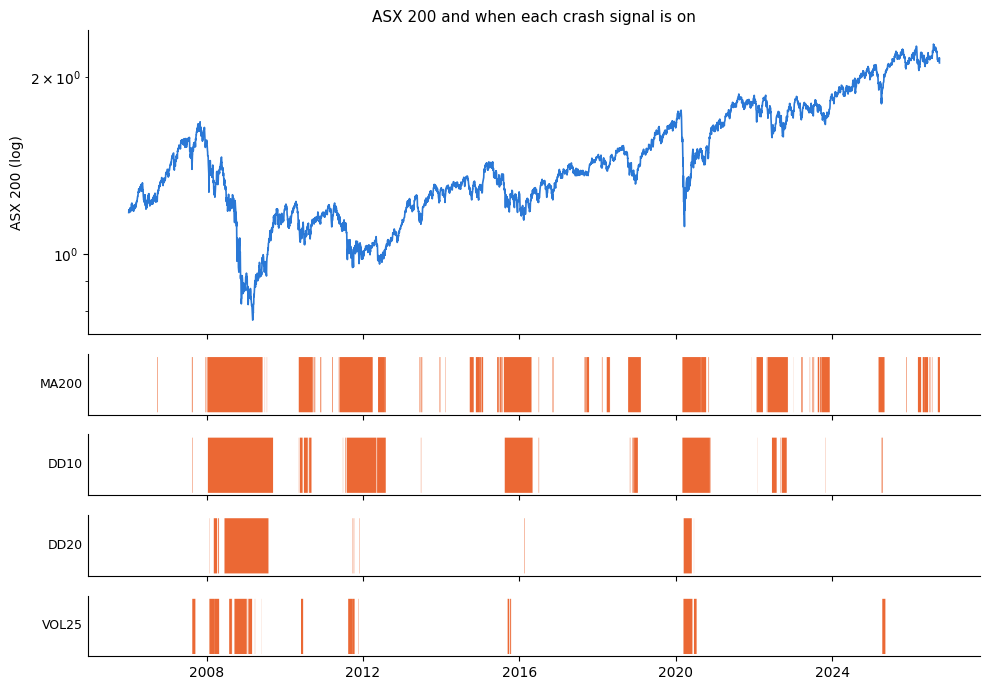

In [4]:
fig, axs = plt.subplots(len(regimes.columns) + 1, 1, figsize=(10, 7), sharex=True,
                        gridspec_kw={"height_ratios": [3] + [0.6] * len(regimes.columns)})
axs[0].plot(level.loc["2006":], color=BLUE, lw=1.2)
axs[0].set_yscale("log")
axs[0].set_title("ASX 200 and when each crash signal is on", fontsize=11)
axs[0].set_ylabel("ASX 200 (log)")
for ax, col in zip(axs[1:], regimes.columns):
    on = regimes[col].loc["2006":]
    ax.fill_between(on.index, 0, on.values, step="post", color=ORANGE, lw=0)
    ax.set_yticks([])
    ax.set_ylabel(col, rotation=0, ha="right", va="center", fontsize=9)
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS / "crash_signals.png", dpi=130)
plt.show()

## 3. The GFC short-selling ban

ASIC banned short selling on 22 September 2008. Covered short selling of non-financial stocks was allowed again from 19 November 2008, but the ban on financial stocks stayed until 25 May 2009. Shorting index futures was not banned.

The single-stock version therefore blocks **new** short entries in all stocks from 22 September to 18 November 2008, and in financial-sector stocks (GICS groups Banks, Insurance and Financial Services) until 24 May 2009. Existing short positions may be kept.

In [5]:
idx, cols = d["adj"].index, d["adj"].columns
fin = d["sector"].reindex(cols).isin(["Banks", "Insurance", "Financial Services", "Diversified Financials"]).values
block = pd.DataFrame(False, index=idx, columns=cols)
block.loc["2008-09-22":"2008-11-18", :] = True
block.loc["2008-11-19":"2009-05-24", fin] = True

s_free = donchian_state(d, N, M)                      # no ban (unrealistic in 2008)
s_ban = donchian_state(d, N, M, short_block=block)    # ban respected
rank = d["adv"].where(d["member"]).rank(axis=1, ascending=False)
top200 = (rank <= 200).shift(1, fill_value=False)
s_ban = s_ban.where((s_ban > 0) | top200, 0.0)
s_free = s_free.where((s_free > 0) | top200, 0.0)
print(f"financial-sector stocks flagged: {int(fin.sum())}")

financial-sector stocks flagged: 112


## 4. Building the variants

* **Long-only:** the baseline, 100% in breakout longs.
* **Long-only + crash index hedge:** when the signal is on, add a short ASX 200 position equal to the long book's beta (rolling 126 days, lagged), which makes the book roughly market-neutral during the crash. 2 bps is charged on changes in hedge size.
* **Long-only + crash stock shorts:** when the signal is on, add a short book in breakdown stocks (top 200) with budget 1.0, the same size as the long book. The ban is respected.
* **References:** the always-on implementable L/S book (long 0.5, short 0.5) and the always-on index-hedged long book from notebook 02.

In [6]:
lo = backtest_budget(s_ban, d, ones, zeros, 20, 2)["net"]
m = axjo.fillna(0.0)
cov = (lo * m).rolling(126, min_periods=60).mean() - lo.rolling(126, min_periods=60).mean() * m.rolling(126, min_periods=60).mean()
beta = (cov / m.rolling(126, min_periods=60).var()).shift(1).fillna(0.9).clip(0, 2)


def index_hedged(on):
    # hedge ratio applied with the same timing as the strategy: signal at t, held over day t+2
    hr = (beta * on).shift(1).fillna(0.0)
    return lo - hr * m - hr.diff().abs().fillna(0) * 2e-4


books = {"Long-only": lo,
         "Always-on L/S (implementable)": backtest_budget(s_ban, d, 0.5 * ones, 0.5 * ones, 20, 2)["net"],
         "Always index-hedged": index_hedged(ones)}
for name in regimes.columns:
    on = regimes[name].reindex(idx).fillna(0)
    books[f"{name} + index hedge"] = index_hedged(on)
    books[f"{name} + stock shorts"] = backtest_budget(s_ban, d, ones, on, 20, 2)["net"]

rows = {}
for name, r in books.items():
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        st = stats(r.loc[sl], ew)
        st["beta_axjo"] = stats(r.loc[sl], axjo)["beta"]
        rows[(name, per)] = st
table = pd.DataFrame(rows).T
table.to_csv(RESULTS / "13_crash_regime_variants.csv")
table[["ann_ret", "ann_vol", "sharpe", "max_dd", "calmar", "alpha", "alpha_t", "beta_axjo"]]

ann_ret  ann_vol  sharpe  max_dd  calmar  alpha  alpha_t  beta_axjo
Long-only                     IS     0.146    0.184   0.796  -0.603   0.243  0.092    3.804      0.708
                              OOS    0.193    0.196   0.983  -0.441   0.437  0.102    5.421      0.928
Always-on L/S (implementable) IS     0.092    0.079   1.164  -0.227   0.404  0.090    3.338     -0.075
                              OOS    0.063    0.082   0.763  -0.115   0.545  0.054    2.172     -0.084
Always index-hedged           IS     0.141    0.130   1.085  -0.429   0.328  0.122    3.665     -0.034
                              OOS    0.144    0.138   1.038  -0.190   0.756  0.105    3.165     -0.025
MA200 + index hedge           IS     0.151    0.153   0.983  -0.433   0.348  0.120    3.474      0.200
                              OOS    0.157    0.164   0.952  -0.294   0.533  0.099    2.836      0.331
MA200 + stock shorts          IS     0.142    0.160   0.888  -0.373   0.382  0.121    2.414      0.118
                              OOS    0.137    0.175   0.787  -0.326   0.421  0.092    1.988      0.217
DD10 + index hedge            IS     0.158    0.157   1.005  -0.438   0.360  0.125    3.723      0.242
                              OOS    0.175    0.178   0.983  -0.291   0.601  0.105    3.345      0.500
DD10 + stock shorts           IS     0.128    0.159   0.801  -0.410   0.311  0.103    2.166      0.167
                              OOS    0.124    0.185   0.670  -0.404   0.306  0.062    1.411      0.397
DD20 + index hedge            IS     0.140    0.174   0.805  -0.554   0.253  0.096    2.987      0.484
                              OOS    0.189    0.188   1.006  -0.304   0.621  0.109    4.353      0.682
DD20 + stock shorts           IS     0.129    0.175   0.739  -0.463   0.278  0.090    1.989      0.427
                              OOS    0.165    0.191   0.864  -0.352   0.468  0.087    2.982      0.670
VOL25 + index hedge           IS     0.136    0.172   0.791  -0.606   0.225  0.094    2.810      0.446
                              OOS    0.182    0.187   0.972  -0.299   0.609  0.103    3.891      0.657
VOL25 + stock shorts          IS     0.145    0.173   0.836  -0.528   0.274  0.104    2.525      0.441
                              OOS    0.167    0.190   0.878  -0.274   0.608  0.092    2.497      0.612

## 5. Choosing on in-sample data only

The goal is to cut drawdowns without giving up too much return, so the selection measure is the **in-sample Calmar ratio** (annual return ÷ maximum drawdown). The Sharpe ratio is shown alongside.

In [7]:
cands = table.xs("IS", level=1)
cands = cands[cands.index.str.contains(r"\+")]
choice = cands["calmar"].idxmax()
print("chosen on IS Calmar:", choice)
cands.sort_values("calmar", ascending=False)[["ann_ret", "sharpe", "max_dd", "calmar"]]

chosen on IS Calmar: MA200 + stock shorts


,ann_ret,sharpe,max_dd,calmar
MA200 + stock shorts,0.142,0.888,-0.373,0.382
DD10 + index hedge,0.158,1.005,-0.438,0.360
MA200 + index hedge,0.151,0.983,-0.433,0.348
DD10 + stock shorts,0.128,0.801,-0.410,0.311
DD20 + stock shorts,0.129,0.739,-0.463,0.278
VOL25 + stock shorts,0.145,0.836,-0.528,0.274
DD20 + index hedge,0.140,0.805,-0.554,0.253
VOL25 + index hedge,0.136,0.791,-0.606,0.225


## 6. Crash and rebound episodes

Total return over each episode. Rebounds matter as much as crashes: a short leg that stays on into the recovery gives back what it saved.

In [8]:
episodes = {
    "GFC crash (Nov 07 - Mar 09)": ("2007-11-01", "2009-03-06"),
    "GFC rebound (Mar 09 - Dec 09)": ("2009-03-09", "2009-12-31"),
    "COVID crash (Feb 20 - Mar 20)": ("2020-02-20", "2020-03-23"),
    "COVID rebound (Mar 20 - Aug 20)": ("2020-03-24", "2020-08-31"),
    "2022 sell-off (Jan - Jun 22)": ("2022-01-01", "2022-06-30"),
}
show = ["Long-only", "Always-on L/S (implementable)", "Always index-hedged", choice,
        choice.replace("index hedge", "stock shorts") if "index hedge" in choice else choice.replace("stock shorts", "index hedge")]
ep = pd.DataFrame({name: {e: (1 + books[name].loc[a:b]).prod() - 1 for e, (a, b) in episodes.items()} for name in show})
ep["ASX 200"] = [(1 + axjo.loc[a:b].fillna(0)).prod() - 1 for a, b in episodes.values()]
ep.to_csv(RESULTS / "13_crash_episodes.csv")
ep.style.format("{:.1%}")

,Long-only,Always-on L/S (implementable),Always index-hedged,MA200 + stock shorts,MA200 + index hedge,ASX 200
GFC crash (Nov 07 - Mar 09),-57.2%,-1.5%,-26.6%,-13.4%,-32.6%,-53.4%
GFC rebound (Mar 09 - Dec 09),66.6%,-12.5%,37.2%,6.4%,47.9%,54.8%
COVID crash (Feb 20 - Mar 20),-43.8%,-1.6%,-14.8%,-12.6%,-21.4%,-36.4%
COVID rebound (Mar 20 - Aug 20),116.0%,12.2%,68.1%,23.9%,66.1%,33.3%
2022 sell-off (Jan - Jun 22),-19.4%,6.9%,-4.5%,-8.0%,-12.0%,-11.8%


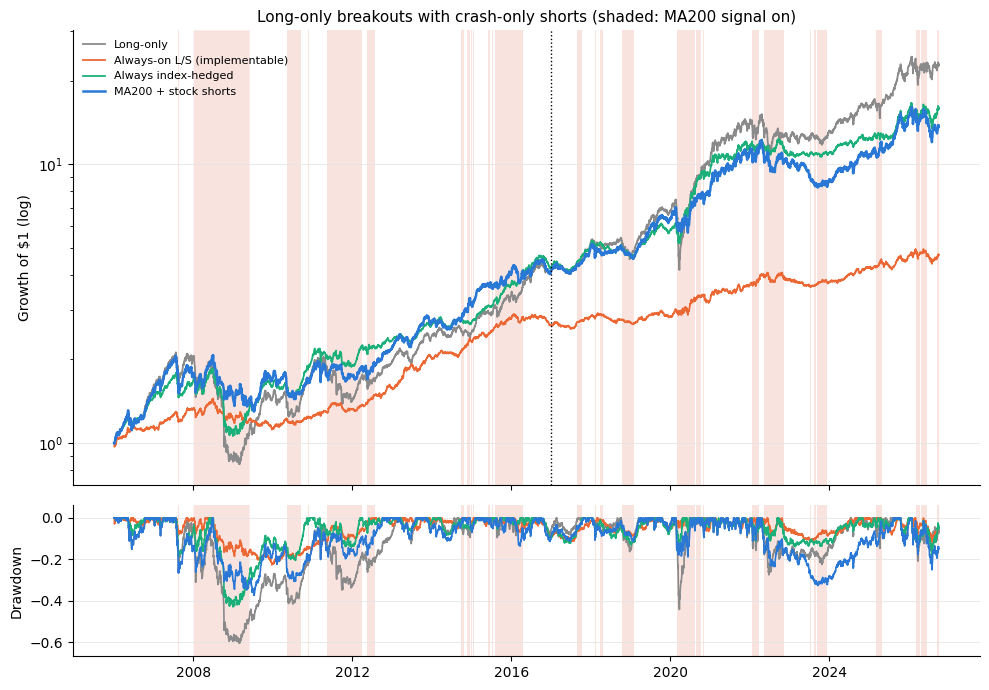

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, c in zip(show[:4], [GREY, ORANGE, AQUA, BLUE]):
    eq = (1 + books[name].loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=1.8 if name == choice else 1.3, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
on = regimes[choice.split(" + ")[0]].loc["2006":]
for ax in axs:
    # shade in axis coordinates (0-1 vertically) so it works on the log scale too
    ax.fill_between(on.index, 0, 1, where=on.values > 0, color=RED_SOFT, alpha=0.5, lw=0, step="post",
                    transform=ax.get_xaxis_transform())
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
axs[0].axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title(f"Long-only breakouts with crash-only shorts (shaded: {choice.split(' + ')[0]} signal on)", fontsize=11)
axs[0].legend(fontsize=8, frameon=False, loc="upper left")
axs[1].set_ylabel("Drawdown")
fig.tight_layout()
fig.savefig(RESULTS / "crash_regime_equity.png", dpi=130)
plt.show()

### Reading the results

**What the chosen rule (`MA200 + stock shorts`, chosen on in-sample Calmar) did:**

| | Long-only | Crash-only shorts | Always index-hedged | Always-on L/S |
|---|---|---|---|---|
| Max DD, IS | −60% | **−37%** | −43% | −23% |
| Max DD, OOS | −44% | **−33%** | −19% | −12% |
| Sharpe, OOS | 0.98 | **0.79** | 1.04 | 0.76 |
| Calmar, OOS | 0.44 | **0.42** | 0.76 | 0.55 |

* **It works in the crashes themselves.** GFC −13% instead of −57%, COVID −13% instead of −44%, 2022 −8% instead of −19%. This holds out-of-sample: the rule was chosen on the GFC alone, and it still cut the COVID crash by about two-thirds.
* **It gives most of it back in the rebounds.** The 200-day signal is slow to switch off. It was still on when markets turned in March 2009 and March 2020, so the breakdown shorts were caught in the sharpest rallies. Long-only made +67% in the GFC rebound and +116% in the COVID rebound; the crash-switched book made +6% and +24%. That is the momentum crash again, in a different form.
* **Whipsaw in choppy markets.** The 200-day signal switches about 8 times a year. In 2022–23 it flipped shorts on and off repeatedly in a sideways market, which produced its worst out-of-sample drawdown (−33%), larger than its COVID loss.
* **Net result out-of-sample:** a lower drawdown than long-only, but a lower return too, and a Calmar no better than long-only (0.42 vs 0.44).
* **The simple always-on index hedge did better out-of-sample** on every risk measure: Sharpe 1.04, max DD −19%, Calmar 0.76. In-sample it looked worse (−43% in the GFC, when small-cap longs fell far more than the ASX 200 hedge), which is why the in-sample rule preferred the crash switch.
* **Index hedge or stock shorts?** For the same signal, the index hedge loses less in rebounds (it is short the market, not the most beaten-down stocks, which rebound hardest). The rarer signals (`VOL25`, `DD20`) did little for the in-sample drawdown (−46% to −61%) and ranked last on in-sample Calmar.

## 7. How much did the ban matter?

The stock-short variant is re-run *ignoring* the GFC ban, to show how much a backtest that ignores it would overstate the result.

In [10]:
sig_name = choice.split(" + ")[0]
on = regimes[sig_name].reindex(idx).fillna(0)
free = backtest_budget(s_free, d, ones, on, 20, 2)["net"]
ban = books[f"{sig_name} + stock shorts"]
pd.DataFrame({
    "ban respected": {"GFC crash": (1 + ban.loc["2007-11-01":"2009-03-06"]).prod() - 1, "IS Sharpe": stats(ban.loc[IS])["sharpe"],
                      "IS max DD": stats(ban.loc[IS])["max_dd"]},
    "ban ignored": {"GFC crash": (1 + free.loc["2007-11-01":"2009-03-06"]).prod() - 1, "IS Sharpe": stats(free.loc[IS])["sharpe"],
                    "IS max DD": stats(free.loc[IS])["max_dd"]},
}).T

,GFC crash,IS Sharpe,IS max DD
ban respected,-0.134,0.888,-0.373
ban ignored,-0.108,0.912,-0.345


## 8. Conclusions

1. **Crash-only shorting does cut crash losses,** in-sample and out-of-sample: the GFC, COVID and 2022 losses all fell by half to two-thirds.
2. **But the crash signals are too slow to switch off.** Rebounds start while the market is still below its 200-day average, so the shorts are caught in the sharpest rallies and give back most of what they saved. Out-of-sample, the crash-switched book's return-to-drawdown ratio was no better than plain long-only.
3. **Timing crashes is hard to do from price alone.** Fast signals arrive too late for the crash; slow ones stay on too long into the rebound. With only two big crashes in 20 years (one in-sample, one out-of-sample), any rule tuned to them is fitted to very few events.
4. **The simplest fix was the best one out-of-sample:** hedge the long book with ASX 200 futures *all the time*. That cut the out-of-sample drawdown to −19% and kept the Sharpe above 1. Its weakness is small-cap crashes (2008), when the large-cap hedge doesn't move enough.
5. **The GFC short-selling ban mattered less than expected** for the stock-short version (GFC loss −13.4% with the ban vs −10.8% without). The ban only blocks *new* short entries, and existing positions could be held. A rule that switched on later in the crash would be hit harder. Index futures were never banned.

**If you want to push this further:**
* An always-on hedge plus a *partial* crash overlay (for example a 50% extra hedge when the signal is on) might combine the steadiness of the hedge with some crash protection, at less rebound cost.
* Add an **exit trigger for rebounds**, such as switching the shorts off when the ASX 200 rises more than X% from its low, to address the main weakness found here. Any such rule has to be chosen on in-sample data only, and with so few crash events the risk of fitting noise is high.
* A hedge that better matches a small-cap book, such as the ASX Small Ordinaries, would reduce the 2008-style mismatch, though futures on it are much less liquid.